# 📘 Notebook 09: Generative Adversarial Networks, a Forger and a Detective

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Papers: Goodfellow et al. (2014) · Radford, Metz and Chintala (2015)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** A small fully connected GAN trains on the 60,000 MNIST digits for 15 epochs: about **15 to 20 minutes** on a laptop processor, a couple of minutes on a Colab GPU. This is close to the setting of the original 2014 paper (fully connected networks on MNIST); the convolutional DCGAN of 2015 and today's StyleGANs produce far sharper images, at much larger cost. GAN training is famously **unstable**: with another random seed the images can be better or worse, and Exercise 2 shows a failure on purpose. To judge the generated digits we use a small digit classifier trained here; it is a rough check of quality and variety, not a standard measure such as the FID score used in research.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain the **adversarial game** between a **generator** and a **discriminator**
- Write the two losses and the alternating training loop
- Watch a generator improve from noise to digits, epoch by epoch
- Check generated samples for **quality** and **variety** with an independent classifier
- Recognise **mode collapse** and other ways GAN training fails
- Compare GANs with the VAE of Notebook 08

> **Prerequisites:** [Notebook 08: Autoencoders and VAEs](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/08_autoencoder_vae.ipynb).
>
> 🔭 **Why this notebook matters:** Yann LeCun called adversarial training "the most interesting idea in machine learning in the last ten years". From 2014 to about 2021, GANs produced the most realistic synthetic images, including the famous faces of people who do not exist, and the deepfakes that raised new ethical questions. Diffusion models (Notebook 12) have since taken over most image generation, but the adversarial idea lives on, for example in image super-resolution and in the discriminators used to train some audio models.

## 1. The papers

> 📄 I. Goodfellow et al., [*Generative Adversarial Nets*](https://arxiv.org/abs/1406.2661), NeurIPS 2014.
>
> 📄 A. Radford, L. Metz and S. Chintala, [*Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks*](https://arxiv.org/abs/1511.06434) (DCGAN), ICLR 2016 (arXiv 2015).

### Intuition first
The VAE (Notebook 08) generated blurry digits because it was trained to match pixels on average. Goodfellow asked a different question: instead of a fixed measure of "how close is this image", why not **learn** the measure?

Two networks play a game:
- the **generator** $G$ turns random noise $z$ into an image: the **forger**;
- the **discriminator** $D$ looks at an image and outputs the probability that it is real: the **detective**.

$D$ is trained to tell real digits from $G$'s fakes. $G$ is trained to fool $D$. As the detective gets sharper, the forger must produce more convincing fakes, and vice versa. If the game reaches a balance, $G$'s images are indistinguishable from real ones, and $D$ can do no better than guess 50%.

$$\min_G \max_D \; \mathbb{E}_{x}\big[\log D(x)\big] + \mathbb{E}_{z}\big[\log(1 - D(G(z)))\big]$$

In practice, the paper's own advice is followed: $G$ maximises $\log D(G(z))$ instead of minimising $\log(1 - D(G(z)))$, which gives stronger gradients early in training when the fakes are obviously fake.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import gzip
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80

MIRROR = "https://ossci-datasets.s3.amazonaws.com/mnist/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(MIRROR + name).read()), dtype=np.uint8, offset=header)
X = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X = X * 2 - 1                      # pixels in [-1, 1], to match the generator's tanh output
print("training images:", tuple(X.shape))

training images: (60000, 784)


## 2. The two networks

In [2]:
NOISE = 64

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(NOISE, 256), nn.LeakyReLU(0.2), nn.Linear(256, 512), nn.LeakyReLU(0.2),
                                 nn.Linear(512, 784), nn.Tanh())
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(784, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
                                 nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(self, x):
        return self.net(x)          # a score; sigmoid(score) = probability "real"

count = lambda m: sum(p.numel() for p in m.parameters())
print("generator weights:", f"{count(Generator()):,}", "  discriminator weights:", f"{count(Discriminator()):,}")

generator weights: 550,416   discriminator weights: 533,505


**What we see.** The two networks are about the same size, roughly **half a million** weights each. Neither sees the other's weights: the generator never looks at a real digit, and learns only through the discriminator's verdicts. The discriminator ends with a single score, not a probability; the sigmoid inside the loss turns it into one.

## 3. The adversarial training loop

Each step has two moves:
1. **Train the detective:** show $D$ a batch of real digits (label 1) and a batch of fakes (label 0).
2. **Train the forger:** generate a batch, and update $G$ so that $D$ calls it real (label 1), while $D$ stays fixed.

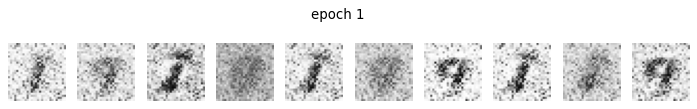

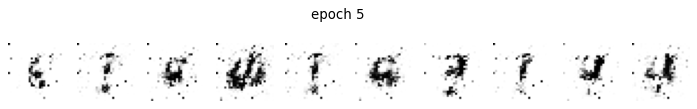

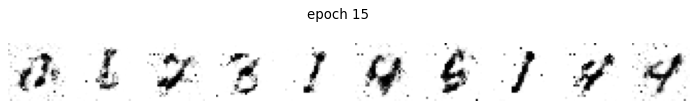

trained in 1252 s


In [3]:
def show(images, title, n=10):
    fig, axes = plt.subplots(1, n, figsize=(n * 1.1, 1.4))
    for ax, img in zip(axes, images[:n]):
        ax.imshow(img.reshape(28, 28), cmap="gray_r", vmin=-1, vmax=1); ax.axis("off")
    plt.suptitle(title, y=1.08)
    plt.show()

def train_gan(epochs=15, batch=128, lr=2e-4, snapshots=(1, 5, 15), seed=0):
    torch.manual_seed(seed)
    G, D = Generator(), Discriminator()
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))   # settings from the DCGAN paper
    opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    fixed = torch.randn(10, NOISE)        # the same noise every epoch, to watch progress
    history, start = [], time.time()
    for epoch in range(1, epochs + 1):
        order = torch.randperm(len(X))
        d_sum = g_sum = real_sum = fake_sum = 0.0
        steps = 0
        for i in range(0, len(X), batch):
            real = X[order[i:i + batch]]
            n = len(real)
            fake = G(torch.randn(n, NOISE))
            # 1. the detective
            d_real, d_fake = D(real), D(fake.detach())
            d_loss = F.binary_cross_entropy_with_logits(d_real, torch.ones(n, 1)) + \
                     F.binary_cross_entropy_with_logits(d_fake, torch.zeros(n, 1))
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
            # 2. the forger
            g_loss = F.binary_cross_entropy_with_logits(D(fake), torch.ones(n, 1))
            opt_g.zero_grad(); g_loss.backward(); opt_g.step()
            d_sum += d_loss.item(); g_sum += g_loss.item()
            real_sum += torch.sigmoid(d_real).mean().item(); fake_sum += torch.sigmoid(d_fake).mean().item()
            steps += 1
        history.append((d_sum / steps, g_sum / steps, real_sum / steps, fake_sum / steps))
        if epoch in snapshots:
            with torch.no_grad():
                show(G(fixed), f"epoch {epoch}")
    print(f"trained in {time.time() - start:.0f} s")
    return G, D, history

G, D, history = train_gan()

**What we see.** The same ten noise vectors, decoded after epochs 1, 5 and 15:
- **Epoch 1:** grey fog with a dark smudge in the middle. The generator has only learned that digits are dark strokes near the centre of a light background.
- **Epoch 5:** sharp but broken strokes with scattered dots: the generator has learned that real digits have crisp black ink, and is still searching for their shapes.
- **Epoch 15:** recognisable digits (a 1, a 3, a 4, a 6, a 7), with ragged edges and some stray pixels.

Notice the contrast with the VAE: even the failures are **sharp**. The discriminator punishes blur immediately, because blur is the easiest sign of a fake. The price is defects of a different kind: specks, broken strokes and some shapes that are not quite any digit.

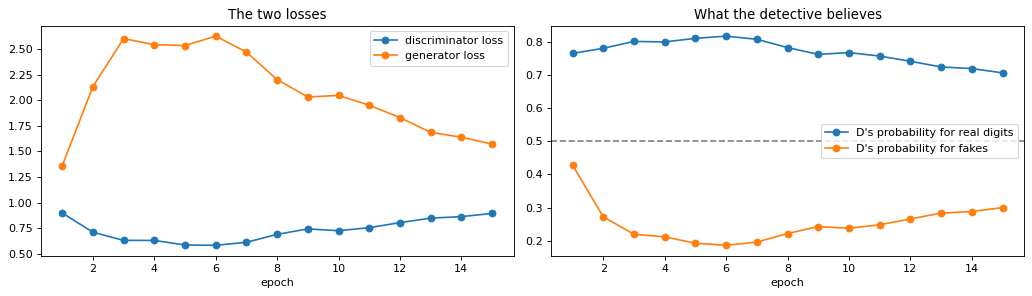

last epoch: D says real digits are real with probability 0.71  and fakes with 0.3


In [4]:
h = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(range(1, len(h) + 1), h[:, 0], marker="o", label="discriminator loss")
axes[0].plot(range(1, len(h) + 1), h[:, 1], marker="o", label="generator loss")
axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].set_title("The two losses")
axes[1].plot(range(1, len(h) + 1), h[:, 2], marker="o", label="D's probability for real digits")
axes[1].plot(range(1, len(h) + 1), h[:, 3], marker="o", label="D's probability for fakes")
axes[1].axhline(0.5, color="grey", linestyle="--")
axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].set_title("What the detective believes")
plt.tight_layout()
plt.show()
print("last epoch: D says real digits are real with probability", round(h[-1, 2], 2), " and fakes with", round(h[-1, 3], 2))

**What we see.** The two losses do **not** go down together, as in ordinary training. In the first epochs the discriminator wins (its loss falls, the generator's rises), because early fakes are easy to spot. From about epoch 6 the generator catches up: its loss falls and the discriminator's rises. On the right, the discriminator's belief about the fakes climbs back from about **0.19** to **0.30**, while its belief about real digits drops from **0.82** to **0.71**. The game is moving towards the balance point of 0.5, but has not reached it after 15 epochs. Neither curve says, on its own, whether the images are good.

## 4. Are the fakes good, and are they varied?

A GAN's losses do not tell us whether its images are good. We need an independent judge. We train a small digit classifier on real MNIST and ask it about 5,000 generated digits: how **confident** it is (quality), and how the generated digits spread across the ten classes (variety). A healthy generator should produce every digit about 10% of the time.

judge's mean confidence: real digits 0.926, generated digits 0.778
share of each digit among generated samples: [0.053 0.218 0.095 0.133 0.131 0.048 0.067 0.113 0.053 0.089]


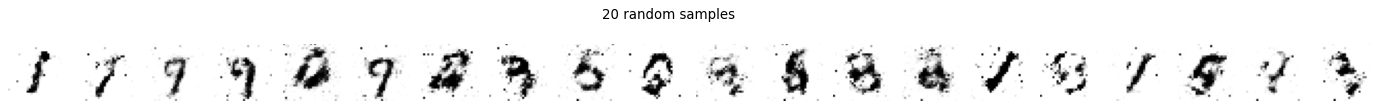

In [5]:
torch.manual_seed(0)
judge = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))
opt = torch.optim.Adam(judge.parameters(), lr=1e-3)
for epoch in range(2):
    order = torch.randperm(len(X))
    for i in range(0, len(X), 256):
        idx = order[i:i + 256]
        loss = F.cross_entropy(judge(X[idx]), y[idx])
        opt.zero_grad(); loss.backward(); opt.step()

def assess(generator, n=5000):
    with torch.no_grad():
        p = judge(generator(torch.randn(n, NOISE))).softmax(1)
    confidence = p.max(1).values.mean().item()
    shares = np.bincount(p.argmax(1).numpy(), minlength=10) / n
    return confidence, shares

with torch.no_grad():
    real_conf = judge(X[:5000]).softmax(1).max(1).values.mean().item()
conf, shares = assess(G)
print(f"judge's mean confidence: real digits {real_conf:.3f}, generated digits {conf:.3f}")
print("share of each digit among generated samples:", np.round(shares, 3))
with torch.no_grad():
    show(G(torch.randn(20, NOISE)), "20 random samples", n=20)

**What we see.** The independent judge is **93%** confident on average about real digits and **78%** about generated ones: most fakes look clearly like some digit, but less clearly than real handwriting. The variety is real but **uneven**: about **22%** of samples are 1s (twice the fair 10%), while 0s, 5s and 8s appear only about **5%** of the time each. This is a mild form of the GAN's classic weakness: the generator favours shapes that fool the discriminator easily (a single straight stroke is the easiest digit to forge) and under-produces harder ones. Full **mode collapse**, where almost every sample is the same digit, is the extreme version of this.

## ⚠️ Common pitfalls

- **Reading the losses as quality.** In a GAN, a low generator loss can mean good images or a weak discriminator. Look at the samples and use an independent check.
- **A discriminator that is too strong.** If $D$ wins completely, $G$ receives almost no gradient and stops improving. Dropout in $D$, equal learning rates and the "non-saturating" generator loss help.
- **Mode collapse.** The generator finds a few outputs that fool $D$ and produces only those. Check the variety of samples, not just their quality.
- **Forgetting `detach()`.** When training $D$, the fakes must be detached, or the discriminator's update also changes the generator.
- **Comparing seeds or runs by one sample grid.** GAN results vary a lot; compare with measures over thousands of samples.

## ✏️ Exercises

### Exercise 1 (Walk through the noise)
Take two noise vectors, decode 10 points on the line between them with the trained generator, and show them. Does the generator morph smoothly between digits, like the VAE?

In [6]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
torch.manual_seed(3)
a, b = torch.randn(NOISE), torch.randn(NOISE)
with torch.no_grad():
    path = torch.stack([(1 - t) * a + t * b for t in np.linspace(0, 1, 10)])
    show(G(path), "from one noise vector to another")
```

*The generator usually morphs smoothly: strokes thicken, loops open and close, one digit turns into another through plausible shapes. Like the VAE's code space, the noise space of a GAN becomes meaningful, although nobody told the generator what each direction should mean.*
</details>

### Exercise 2 (Break it on purpose)
Train a GAN where the discriminator learns **ten times faster** than the generator (`lr` of `2e-3` for $D$, `2e-4` for $G$) for 5 epochs. Assess it with the judge. What happens to quality and variety?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def train_unbalanced(epochs=5, batch=128):
    torch.manual_seed(0)
    G2, D2 = Generator(), Discriminator()
    opt_g = torch.optim.Adam(G2.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D2.parameters(), lr=2e-3, betas=(0.5, 0.999))
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            real = X[order[i:i + batch]]; n = len(real)
            fake = G2(torch.randn(n, NOISE))
            d_loss = F.binary_cross_entropy_with_logits(D2(real), torch.ones(n, 1)) + F.binary_cross_entropy_with_logits(D2(fake.detach()), torch.zeros(n, 1))
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
            g_loss = F.binary_cross_entropy_with_logits(D2(fake), torch.ones(n, 1))
            opt_g.zero_grad(); g_loss.backward(); opt_g.step()
    return G2

G2 = train_unbalanced()
conf2, shares2 = assess(G2)
print("confidence", round(conf2, 3), " shares", np.round(shares2, 3))
with torch.no_grad():
    show(G2(torch.randn(10, NOISE)), "unbalanced training")
```

*An over-powerful detective tends to hurt the forger: images are worse, or the variety shrinks as the generator retreats to a few outputs that still fool the discriminator. The exact failure changes from run to run, which is exactly what makes GAN training difficult.*
</details>

### Exercise 3 (GAN against VAE)
Using the judge, compare 5,000 GAN samples with 5,000 samples from a VAE: train the `VAE` class of Notebook 08 for 3 epochs here (remember the pixels in this notebook are in [-1, 1]; map them back with `(X + 1) / 2`). Which model's samples does the judge find more convincing?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
class VAE(nn.Module):
    def __init__(self, code=16):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(784, 256), nn.ReLU())
        self.mu, self.log_var = nn.Linear(256, code), nn.Linear(256, code)
        self.decoder = nn.Sequential(nn.Linear(code, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, x):
        h = self.body(x); mu, lv = self.mu(h), self.log_var(h)
        return self.decoder(mu + torch.exp(0.5 * lv) * torch.randn_like(mu)), mu, lv

X01 = (X + 1) / 2
torch.manual_seed(0)
vae = VAE()
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
for _ in range(3):
    order = torch.randperm(len(X01))
    for i in range(0, len(X01), 256):
        x = X01[order[i:i + 256]]
        r, mu, lv = vae(x)
        loss = F.binary_cross_entropy(r, x, reduction="sum") / len(x) - 0.5 * torch.sum(1 + lv - mu ** 2 - lv.exp()) / len(x)
        opt.zero_grad(); loss.backward(); opt.step()
vae_sampler = lambda z: vae.decoder(torch.randn(len(z), 16)) * 2 - 1
conf_v, shares_v = assess(vae_sampler)
print("judge's confidence: GAN", round(conf, 3), "  VAE", round(conf_v, 3))
```

*The judge usually finds the GAN's sharp digits more convincing than the VAE's blurry ones, while the VAE tends to cover all digits more evenly. This trade-off, sharpness against coverage, is the classic difference between the two families, and one reason diffusion models, which manage both, took over.*
</details>

## 🔑 Key takeaways

- A **GAN** trains a **generator** to fool a **discriminator** that is trained to catch it; the discriminator is a learned measure of realism.
- Training **alternates** between the two networks and is delicate: balance, learning rates and loss choices matter.
- Losses say little about image quality; judge GANs on **samples**, for **quality** and **variety**.
- **Mode collapse** (little variety) is the characteristic GAN failure.
- GANs give **sharper** images than VAEs; diffusion models (Notebook 12) later combined sharpness with stable training.

---
**Next:** *Notebook 10: U-Net*, where a network must label every pixel of an image, and skip connections carry fine detail from the encoder to the decoder.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*